<a href="https://colab.research.google.com/github/JAZAgT/guia07_rogz/blob/main/unidad-3-transformers/Lab03_Arquitectura_BERT_BETO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NLP + Transformers


---
## 1) Visualización de la Configuración de BERT 👀

In [1]:
#!pip install transformers

In [2]:
from transformers import BertConfig, BertModel

Cargar la configuración del modelo BERT en español

In [3]:
config = BertConfig.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")
print("Número de capas de BERT:", config.num_hidden_layers)

Número de capas de BERT: 12


Cargar el modelo para visualizar su arquitectura

In [4]:
model = BertModel.from_pretrained("dccuchile/bert-base-spanish-wwm-cased", output_hidden_states=True)
print(model)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(31002, 768, padding_idx=1)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

### Análisis — Sección 1: Configuración de BERT

**1. Los tres módulos principales de BERT**

En la salida de `print(model)` se observan tres bloques principales dentro de `BertModel`:

- **`embeddings` (BertEmbeddings):** convierte cada token de entrada en un vector denso, sumando tres tipos de embeddings — `word_embeddings` (vocabulario), `position_embeddings` (posición dentro de la secuencia) y `token_type_embeddings` (segmento A/B) — seguido de un `LayerNorm` y `Dropout`.
- **`encoder` (BertEncoder):** es el bloque central, compuesto por una `ModuleList` de 12 instancias de `BertLayer` apiladas secuencialmente (coincide con `config.num_hidden_layers = 12`). Cada capa procesa y refina las representaciones contextuales de toda la secuencia.
- **`pooler` (BertPooler):** toma únicamente el vector correspondiente al token `[CLS]` de la última capa, lo pasa por una capa `Linear(768, 768)` y una activación `Tanh`, produciendo un resumen de dimensión fija de toda la oración (usado típicamente en tareas de clasificación).

**2. Subcapas dentro de un `BertLayer`**

Cada `BertLayer` contiene dos bloques, cada uno con su propia conexión residual + normalización:

- **Mecanismo de atención (`BertAttention`):**
  - `BertSelfAttention`: contiene las capas `query`, `key` y `value` (tres `Linear(768, 768)` independientes) que proyectan la entrada en las matrices Q, K y V usadas para calcular la autoatención.
    - `BertSelfOutput`: recibe la salida de la atención, la pasa por una `Linear(768, 768)`, le aplica `Dropout` y luego la **suma (conexión residual)** con la entrada original de la capa antes de pasar por un `LayerNorm`.
    - **Red Feed-Forward (`BertIntermediate` + `BertOutput`):**
      - `BertIntermediate`: expande la dimensión con una `Linear(768, 3072)` seguida de la activación GELU.
        - `BertOutput`: contrae de vuelta con `Linear(3072, 768)`, aplica `Dropout`, y nuevamente suma la **conexión residual** (la salida del bloque de atención) antes de pasar por su propio `LayerNorm`.

        **3. Dimensión oculta (hidden_size)**

        El modelo utiliza `hidden_size = 768` (valor estándar de BERT-base). Esto es visible tanto en `config.hidden_size` como en las dimensiones de entrada/salida de todas las capas `Linear` de `query`, `key`, `value` y `BertSelfOutput.dense`, que se imprimen como `Linear(in_features=768, out_features=768, bias=True)`.

## 2) Visualización de las Capas y Hidden States 🔍

In [5]:
from transformers import BertTokenizer
import torch

Cargar tokenizer y modelo BERT en español

In [6]:
tokenizer = BertTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")
model = BertModel.from_pretrained("dccuchile/bert-base-spanish-wwm-cased", output_hidden_states=True)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Texto de ejemplo

In [7]:
text = "El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas."
inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)
outputs = model(**inputs)

In [8]:
print(inputs)

{'input_ids': tensor([[    4,  1162,  4196,  1008,  4262,  8643, 16685, 21291, 24010,  1057,
          8926,  4444,  1040,  1797,  1008,  3008,  1042, 27994,  1354, 12956,
          1009,     5]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}


In [9]:
print(outputs)

BaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=tensor([[[-0.3688, -0.2218, -0.6865,  ..., -0.4430,  0.2883,  0.1794],
         [-0.2616, -0.0662, -0.6243,  ..., -0.5904,  0.6507,  0.2768],
         [-0.2415, -0.2261, -0.6785,  ..., -0.1096,  0.0910,  0.5395],
         ...,
         [-1.4393, -0.1986, -0.5770,  ..., -0.5261,  0.0716,  1.0376],
         [-0.7026,  0.3509, -0.4953,  ..., -0.3322,  0.3734,  0.1284],
         [-1.2273, -0.4597, -1.0296,  ..., -0.6864,  0.9237, -0.5841]]],
       grad_fn=<NativeLayerNormBackward0>), pooler_output=tensor([[ 5.1460e-01,  1.4085e-01, -1.1282e-01,  1.3508e-01,  4.4195e-01,
          2.2014e-01, -3.6180e-01, -1.9863e-01,  1.0947e-01,  3.4712e-01,
          3.6002e-01, -2.4028e-01,  4.2768e-01, -3.1439e-01, -3.6554e-01,
          1.5357e-01,  4.5899e-02, -4.5982e-02,  3.4742e-01,  2.1700e-01,
         -9.6863e-02,  2.4965e-01,  7.2584e-01,  2.3798e-01, -2.6819e-01,
         -6.0504e-02,  8.0974e-02, -3.6840e-01,  5.9944e-02,  2.507

Extraer los hidden states


In [10]:
hidden_states = outputs.hidden_states
print("Número de capas (incluyendo la capa de embedding):", len(hidden_states))

Número de capas (incluyendo la capa de embedding): 13


In [11]:
print("Shape de hidden_states[0]:", hidden_states[0].shape)

Shape de hidden_states[0]: torch.Size([1, 22, 768])


Por ejemplo, si BERT base tiene 12 capas, se imprimirá 13 (1 de embedding + 12 codificadores)

### Análisis — Sección 2: Tokenización y Hidden States

**1. El diccionario `inputs`**

- **`input_ids`**: la secuencia de identificadores numéricos del vocabulario de BETO que representan cada subtoken (wordpiece) de la oración, incluyendo los tokens especiales `[CLS]` (inicio) y `[SEP]` (fin) que el tokenizador agrega automáticamente.
- **`token_type_ids`**: identifica a qué "segmento" pertenece cada token, usado originalmente para distinguir la oración A de la oración B en tareas como Next Sentence Prediction o Question Answering. Como aquí se procesa una sola oración, todos sus valores son `0` (un único segmento).
- **`attention_mask`**: máscara binaria que indica qué posiciones corresponden a tokens reales (`1`) frente a relleno/padding (`0`). Como la oración se procesó sola, sin necesidad de rellenar hasta un largo común con otra secuencia del batch, **todos los valores son 1**: cada token participa plenamente en el cálculo de autoatención, sin ninguna posición enmascarada.

**2. Por qué `len(hidden_states)` es 13 y no 12**

`output_hidden_states=True` no solo devuelve la salida de las 12 capas del `encoder` (`config.num_hidden_layers = 12`), sino que agrega **en la posición `[0]`** la salida de la capa de `embeddings`, es decir, las representaciones de los tokens *antes* de que atraviesen cualquier bloque `BertLayer`. Por lo tanto:

- `hidden_states[0]` → salida de `embeddings` (vector inicial de cada token, sin contexto).
- `hidden_states[1]` a `hidden_states[12]` → salida de cada una de las 12 capas del encoder, sucesivamente más contextualizada.

Esto da 1 + 12 = **13** tensores en total.

**3. Las tres dimensiones de `hidden_states[0].shape`**

Al ejecutar la celda agregada, el resultado real fue `torch.Size([1, 22, 768])`. El tensor tiene forma `[batch_size, sequence_length, hidden_size]`:

- **`batch_size` = 1**: número de oraciones procesadas simultáneamente; aquí es 1 porque se tokenizó una sola oración.
- **`sequence_length` = 22**: cantidad de tokens (incluyendo `[CLS]` y `[SEP]`) en los que el tokenizador dividió la oración de entrada; este valor salió más alto que el número de palabras de la oración porque BETO fragmenta en subtokens (wordpieces) palabras como "Samsung" o "S21".
- **`hidden_size` = 768**: la dimensión fija de cada vector de representación, igual para todas las capas del modelo.

## 3) Diagrama Conceptual y Pseudocódigo 🙌

Pseudocódigo del mecanismo de Self-Attention

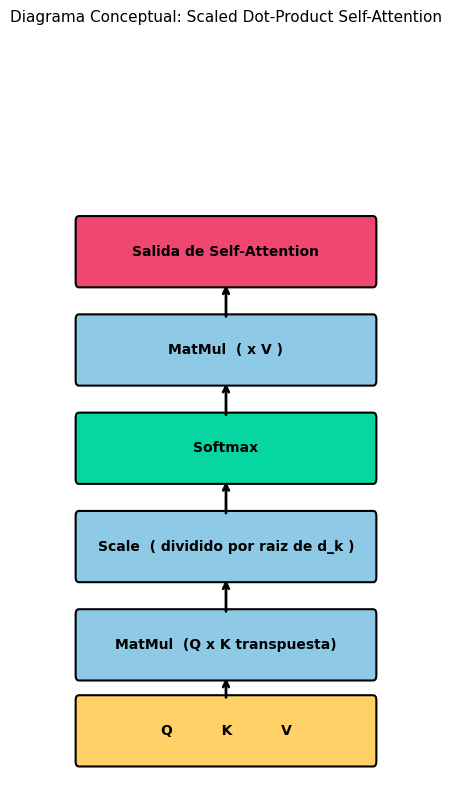

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patches as mpatches
fig, ax = plt.subplots(figsize=(4.5, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis('off')
boxes = [(0.3, 'Q          K          V', '#ffd166'), (1.7, 'MatMul  (Q x K transpuesta)', '#8ecae6'), (3.3, 'Scale  ( dividido por raiz de d_k )', '#8ecae6'), (4.9, 'Softmax', '#06d6a0'), (6.5, 'MatMul  ( x V )', '#8ecae6'), (8.1, 'Salida de Self-Attention', '#ef476f')]
for (y, text, color) in boxes: rect = mpatches.FancyBboxPatch((1.5, y), 7, 1.0, boxstyle='round,pad=0.08', linewidth=1.5, edgecolor='black', facecolor=color); ax.add_patch(rect); ax.text(5, y + 0.5, text, ha='center', va='center', fontsize=10, fontweight='bold')
arrows = [(1.3, 1.7), (2.7, 3.3), (4.3, 4.9), (5.9, 6.5), (7.5, 8.1)]
for (y1, y2) in arrows: ax.annotate('', xy=(5, y2), xytext=(5, y1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Diagrama Conceptual: Scaled Dot-Product Self-Attention', fontsize=11, pad=15)
plt.tight_layout()
plt.savefig('diagrama_self_attention.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretación del diagrama**

El diagrama muestra el flujo de datos del mecanismo de Self-Attention de abajo hacia arriba: a partir de las matrices Q (query), K (key) y V (value) obtenidas de las proyecciones lineales, primero se calcula la similitud entre cada query y cada key (`MatMul Q·Kᵀ`), se escala el resultado dividiendo entre `√d_k` para estabilizar los gradientes, se normaliza con `Softmax` para obtener los pesos de atención (que suman 1 por fila), y finalmente esos pesos se usan para ponderar los valores `V` (`MatMul ·V`), produciendo la salida contextualizada de la capa. Este es el mismo flujo que ejecuta internamente cada bloque `BertSelfAttention` observado en la Sección 1, una vez por cada una de las 12 capas del encoder.

**Pseudocódigo paso a paso de `Attention(Q, K, V) = softmax(QK^T / √dk) V`**

```
Entrada: X  (matriz de embeddings de la secuencia, forma [seq_len, d_model])

1. Proyecciones lineales (usando los pesos aprendidos W_Q, W_K, W_V):
      Q = X · W_Q      # forma [seq_len, d_k]
            K = X · W_K      # forma [seq_len, d_k]
                  V = X · W_V      # forma [seq_len, d_v]
                     → En BERT, estas proyecciones son exactamente las capas query, key y value
                          de BertSelfAttention.

                          2. Puntajes de atención (similitud entre cada query y cada key):
                                scores = Q · K^T        # forma [seq_len, seq_len]

                                3. Escalado (evita gradientes muy pequeños cuando d_k es grande):
                                      scores_escalados = scores / sqrt(d_k)

                                      4. Normalización por fila (softmax):
                                            attention_weights = softmax(scores_escalados, dim=-1)
                                                  # cada fila suma 1.0: son los "pesos de atención" de un token hacia todos los demás

                                                  5. Suma ponderada de los valores:
                                                        salida_atención = attention_weights · V     # forma [seq_len, d_v]

                                                        6. (Multi-Head) Se repiten los pasos 1-5 en paralelo para cada una de las
                                                           cabezas de atención, se concatenan los resultados y se proyectan con
                                                              una capa lineal adicional (W_O).

                                                              7. Conexión residual + normalización (BertSelfOutput):
                                                                    salida_capa = LayerNorm(salida_atención_proyectada + X)
                                                                    ```

                                                                    ### Análisis — Sección 3

                                                                    **1. Vínculo con `BertSelfAttention`**

                                                                    Cada paso de este pseudocódigo tiene una correspondencia directa con los módulos observados en la Sección 1: las matrices `W_Q`, `W_K`, `W_V` son literalmente las capas `query`, `key` y `value` (`Linear(768, 768)`) impresas dentro de cada `BertSelfAttention`; el escalado y el softmax ocurren dentro del método `forward()` de ese mismo módulo; y la suma residual + `LayerNorm` del paso 7 es exactamente lo que realiza `BertSelfOutput` inmediatamente después.

                                                                    **2. Por qué el diagrama y el pseudocódigo se ubican al cierre del laboratorio**

                                                                    El laboratorio sigue una progresión de lo concreto a lo abstracto: primero se observó la arquitectura ya instanciada (Sección 1: los módulos y sus dimensiones), luego se inspeccionaron los tensores reales que fluyen a través de ella en una ejecución concreta (Sección 2: `inputs`, `outputs`, `hidden_states`). Solo después de ver ambas caras —la estructura y los datos reales— tiene sentido formalizar la operación matemática que las conecta: el pseudocódigo de Self-Attention explica *cómo* `BertSelfAttention` transforma el `hidden_states[i]` de una capa en el `hidden_states[i+1]` de la siguiente, cerrando el ciclo entre lo que el modelo *es* (Sección 1), lo que el modelo *produce* (Sección 2) y lo que el modelo *calcula internamente* para producirlo (Sección 3).